In [ ]:
# Figure 3: Int Var Spatial Metrics

In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np 

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib
import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import cmaps
from cmcrameri import cm 
import matplotlib.pyplot as plt
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from matplotlib.gridspec import GridSpec
import xarray as xr

from fast_o3_iv import utils as tools
from fast_o3_iv.config import PROCESSED_DATA_DIR


In [2]:
ds = xr.open_dataset(PROCESSED_DATA_DIR / "figure_data" / "Figure3_local_metrics_fields.nc")

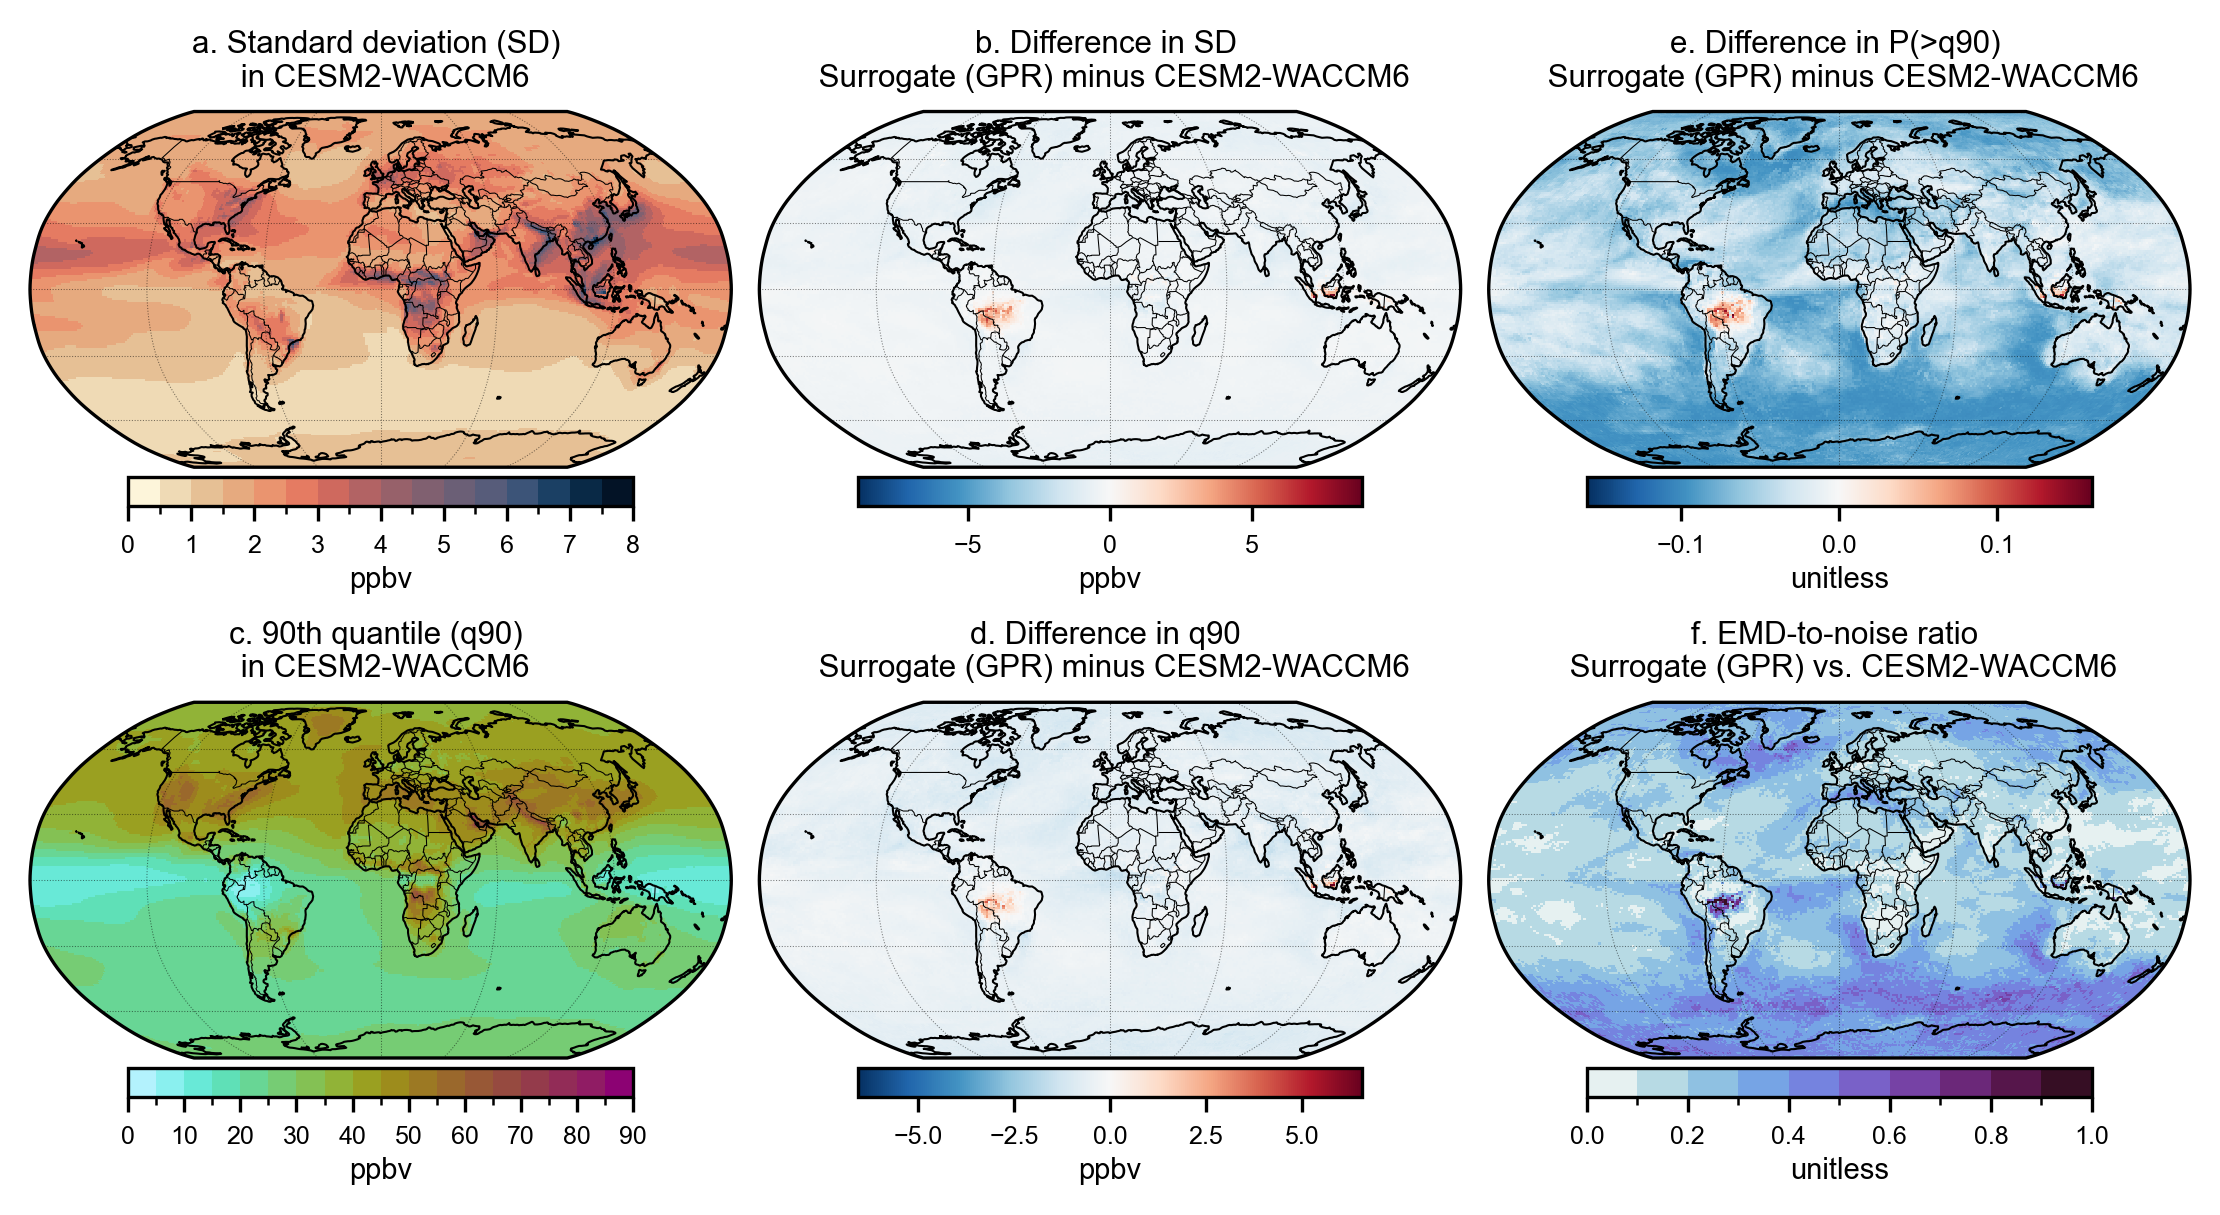

In [ ]:
tools.set_matplotlib_font("Arial")
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
color = 'black'

def style_map(ax):
    """helper to style the maps in each subplot (same as fig2)"""
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl


def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    """helper to add a colorbar to each subplot (same as fig2)"""
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2)  # label close
    return cb

# create the figure
fig_width_in = 9
fig_height_in = 4
fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(
    2, 3,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.60, wspace=0.04
)

proj = ccrs.Robinson(central_longitude=0)

# Row 1
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[0, 1], projection=proj)

# Row 2
ax3 = fig.add_subplot(gs1[1, 0], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

# Row 3
ax5 = fig.add_subplot(gs1[0, 2], projection=proj)
ax6 = fig.add_subplot(gs1[1, 2], projection=proj)

fig.canvas.draw()


axes = [ax1, ax2, ax3, ax4, ax5, ax6]

titles= ["a. Standard deviation (SD) \n in CESM2-WACCM6", 
         "b. Difference in SD \n Surrogate (GPR) minus CESM2-WACCM6", 
         "c. 90th quantile (q90) \n in CESM2-WACCM6", 
         "d. Difference in q90 \n Surrogate (GPR) minus CESM2-WACCM6", 
         "e. Difference in P(>q90) \n Surrogate (GPR) minus CESM2-WACCM6", 
         "f. EMD-to-noise ratio \n Surrogate (GPR) vs. CESM2-WACCM6", 
]


for ax, t in zip(axes, titles):
    ax.set_title(t, color="black", fontsize=7.5)
    style_map(ax)


# standard deviation
vmax = 8
vmin = 0
step = 0.5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.lipari_r
colors = base(np.linspace(0, 1, n_bins))
cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m1 = ds['sd_true'].plot.pcolormesh(
    ax=ax1, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax1, m1, label="ppbv")

# sd diff
m2 = ds['sd_diff'].plot.pcolormesh(
    ax=ax2, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax2, m2, label="ppbv")


# q90 
vmax = 90
vmin = 0
step = 5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.hawaii_r
colors = base(np.linspace(0, 1, n_bins))
cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m3 = ds['q90_true'].plot.pcolormesh(
    ax=ax3, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # keeps  ax.set_title()
)
add_panel_cbar(fig, ax3, m3, label="ppbv")

# q90 diff

m4 = ds['q90_diff'].plot.pcolormesh(
    ax=ax4, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax4, m4, label="ppbv")


# pgtq90 diff 

m5 = ds['pgtq90_diff'].plot.pcolormesh(
    ax=ax5, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax5, m5, label="unitless")


# emd-to-noise
vmax = 1
vmin = 0
step = 0.1
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cmaps.cmocean_dense
colors = base(np.linspace(0, 1, n_bins))
cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)


m6 = ds['emdtonoise'].plot.pcolormesh(
    ax=ax6, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    #vmin=0, vmax=1, 
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax6, m6, label="unitless")

#for ax in axes:
#    add_hatch(ax)
